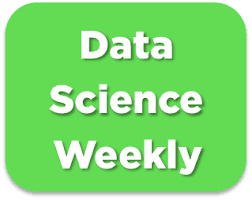

# Challenge : predict conversions 🏆🏆

This is the template that shows the different steps of the challenge. In this notebook, all the training/predictions steps are implemented for a very basic model (logistic regression with only one variable). Please use this template and feel free to change the preprocessing/training steps to get the model with the best f1-score ! May the force be with you 🧨🧨  

**For a detailed description of this project, please refer to *02-Conversion_rate_challenge.ipynb*.**

# Import libraries

In [278]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# setting Jedha color palette as default
pio.templates["jedha"] = go.layout.Template(
    layout_colorway=[
        "#4B9AC7",
        "#4BE8E0",
        "#9DD4F3",
        "#97FBF6",
        "#2A7FAF",
        "#23B1AB",
        "#0E3449",
        "#015955",
    ]
)
pio.templates.default = "jedha"
pio.renderers.default = "svg"  # to be replaced by "iframe" if working on JULIE
from IPython.display import display

# Read file with labels

In [ ]:
df = pd.read_csv("Walmart_Store_sales.csv")
print('Set with labels :', df.shape)

Set with labels (our train) : (150, 8)


Le dataset est tout petit. Nous devons conserver toutes les lignes pour l'exploiter en machine learning.

# Explore dataset

In [293]:
print(f"Display of dataset: {display(df.head())}")

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,6.0,18-02-2011,1572117.54,NaN,59.61,3.04,214.78,6.86
1,13.0,25-03-2011,1807545.43,0.0,42.38,3.44,128.62,7.47
2,17.0,27-07-2012,NaN,0.0,NaN,NaN,130.72,5.94
3,11.0,NaN,1244390.03,0.0,84.57,NaN,214.56,7.35
4,6.0,28-05-2010,1644470.66,0.0,78.89,2.76,212.41,7.09


Display of dataset: None


Les formats sont loin d'être optimisés.

In [281]:
# Basic stats
print(f"Number of rows : \t dataset {df.shape[0]}")
print(f"Number of columns : \t dataset {df.shape[1]}")

print()
print("Basics statistics: df dataset")
df_desc = df.describe(include='all') # numeric variables and catégorielles
display(df_desc)

print("Percentage of missing values")
df_missing_values = df.isnull().sum()/df.shape[0]*100

print()
print(f"df : \n{df_missing_values}")

Number of rows : 	 dataset 150
Number of columns : 	 dataset 8

Basics statistics: df dataset


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,150.000000,132,1.360000e+02,138.000000,132.000000,136.000000,138.000000,135.000000
unique,NaN,85,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,07-01-2011,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN
mean,9.866667,NaN,1.249536e+06,0.079710,61.398106,3.320853,179.898509,7.598430
std,6.231191,NaN,6.474630e+05,0.271831,18.378901,0.478149,40.274956,1.577173
min,1.000000,NaN,2.689290e+05,0.000000,18.790000,2.514000,126.111903,5.143000
25%,4.000000,NaN,6.050757e+05,0.000000,45.587500,2.852250,131.970831,6.597500
50%,9.000000,NaN,1.261424e+06,0.000000,62.985000,3.451000,197.908893,7.470000
75%,15.750000,NaN,1.806386e+06,0.000000,76.345000,3.706250,214.934616,8.150000


Percentage of missing values

df : 
Store            0.000000
Date            12.000000
Weekly_Sales     9.333333
Holiday_Flag     8.000000
Temperature     12.000000
Fuel_Price       9.333333
CPI              8.000000
Unemployment    10.000000
dtype: float64


Nous observons des valeurs manquantes sur toutes les colonnes excepté store.

In [ ]:
print("Duplicate rows:")
df.duplicated().sum()

Duplicate rows:


np.int64(0)

Convertir les noms de colonnes en minuscules.

In [284]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


### détecter les outlyers

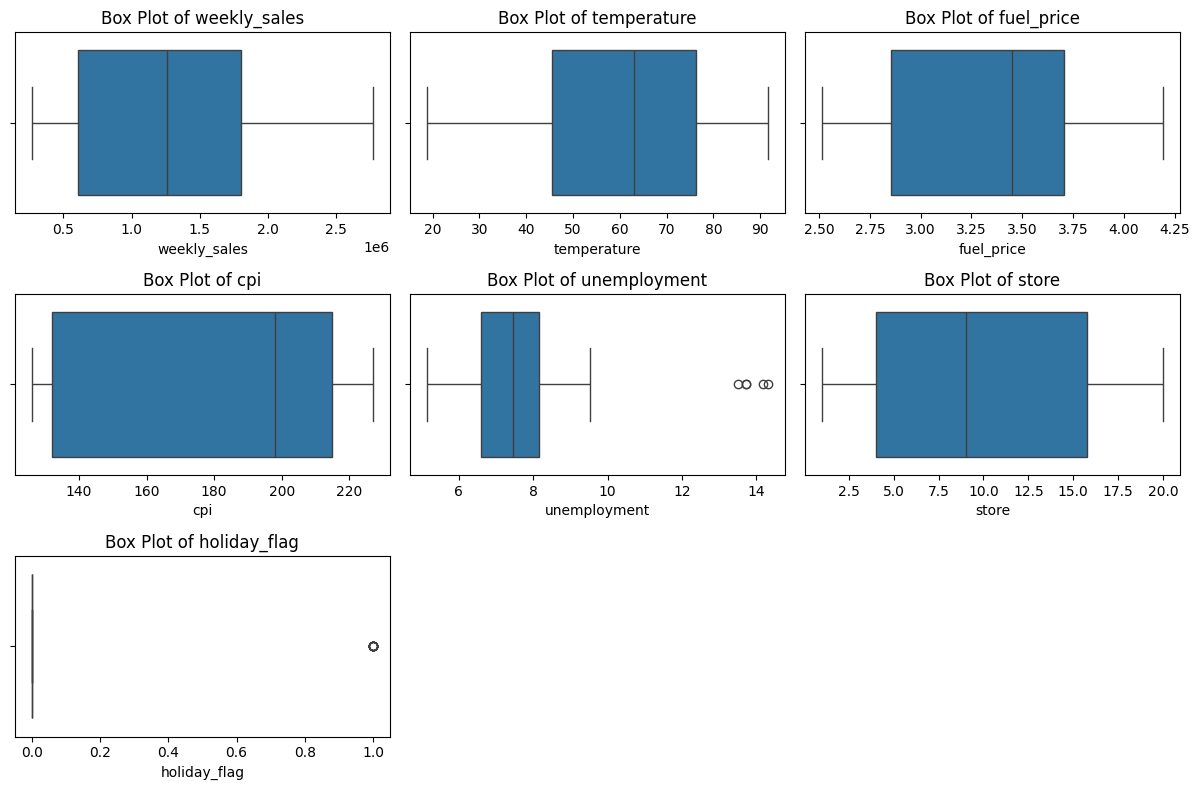

In [285]:
# Create box plots for the 'value', 'useful_area', 'time_on_market', 'interior_quality',
# 'rooms', and 'garages' variables to visually inspect for outliers
plt.figure(figsize=(12, 8))
plt.subplot(3, 3, 1)
sns.boxplot(x=df['weekly_sales'])
plt.title('Box Plot of weekly_sales')
plt.subplot(3, 3, 2)
sns.boxplot(x=df['temperature'])
plt.title('Box Plot of temperature')
plt.subplot(3, 3, 3)
sns.boxplot(x=df['fuel_price'])
plt.title('Box Plot of fuel_price')
plt.subplot(3, 3, 4)
sns.boxplot(x=df['cpi'])
plt.title('Box Plot of cpi')
plt.subplot(3, 3, 5)
sns.boxplot(x=df['unemployment'])
plt.title('Box Plot of unemployment')
plt.subplot(3, 3, 6)
sns.boxplot(x=df['store'])
plt.title('Box Plot of store')
plt.subplot(3, 3, 7)
sns.boxplot(x=df['holiday_flag'])
plt.title('Box Plot of holiday_flag')
plt.tight_layout()
plt.show()



# clean dataset

traitement des valeurs manquantes

Cette ligne remplace les valeurs nulles par la valeur la plus fréquente (0 ou 1), puis convertit la colonne en entiers.

In [ ]:
df['holiday_flag'] = df['holiday_flag'].fillna(df['holiday_flag'].mode()[0]).astype(int)


TODO à terminer

In [ ]:
print("Percentage of missing values")
df_missing_values = df.isnull().sum()/df.shape[0]*100

print()
print(f"df : \n{df_missing_values}")

In [292]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)

Conversion des catégories en integer

In [ ]:
categories = ['store', 'holiday_flag']
df[categories] = df[categories].astype(int)

Conversion des dates au format date time

In [ ]:
type('date')
df['date'] = pd.to_datetime(df['date'], format = "%Y-%m-%d")

Arrondir les colonnes numériques à 2 chiffres

In [ ]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)

In [ ]:
print(df[categories + ['date']].dtypes)

# EDA

In [286]:
# Try correlation on all columns (numeric columns will be used)
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix)

                 store  weekly_sales  holiday_flag  temperature  fuel_price  \
store         1.000000      0.115964     -0.025545    -0.260421    0.183379   
weekly_sales  0.115964      1.000000      0.037037    -0.165991   -0.019087   
holiday_flag -0.025545      0.037037      1.000000    -0.187922   -0.117447   
temperature  -0.260421     -0.165991     -0.187922     1.000000    0.048943   
fuel_price    0.183379     -0.019087     -0.117447     0.048943    1.000000   
cpi          -0.587729     -0.287227      0.171969     0.137936   -0.159881   
unemployment  0.224478      0.055191      0.096934    -0.030122    0.086241   

                   cpi  unemployment  
store        -0.587729      0.224478  
weekly_sales -0.287227      0.055191  
holiday_flag  0.171969      0.096934  
temperature   0.137936     -0.030122  
fuel_price   -0.159881      0.086241  
cpi           1.000000     -0.348072  
unemployment -0.348072      1.000000  


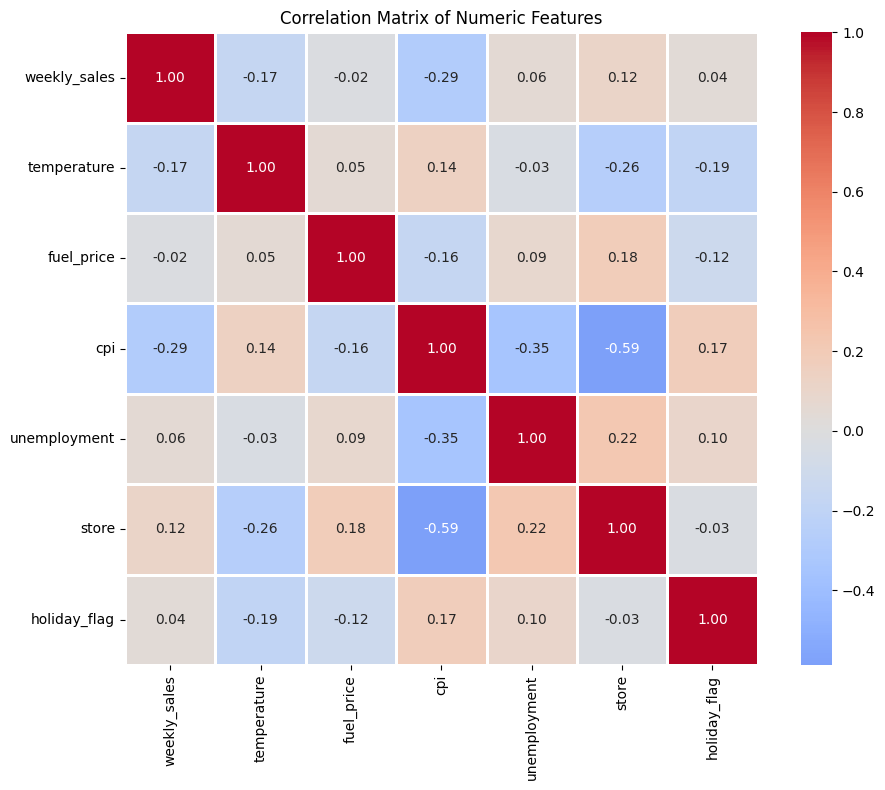

In [287]:
# Plot the correlation matrix as a heatmap
cols = ['weekly_sales', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'store', 'holiday_flag']

corr_matrix = df[cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True, linewidths=1)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

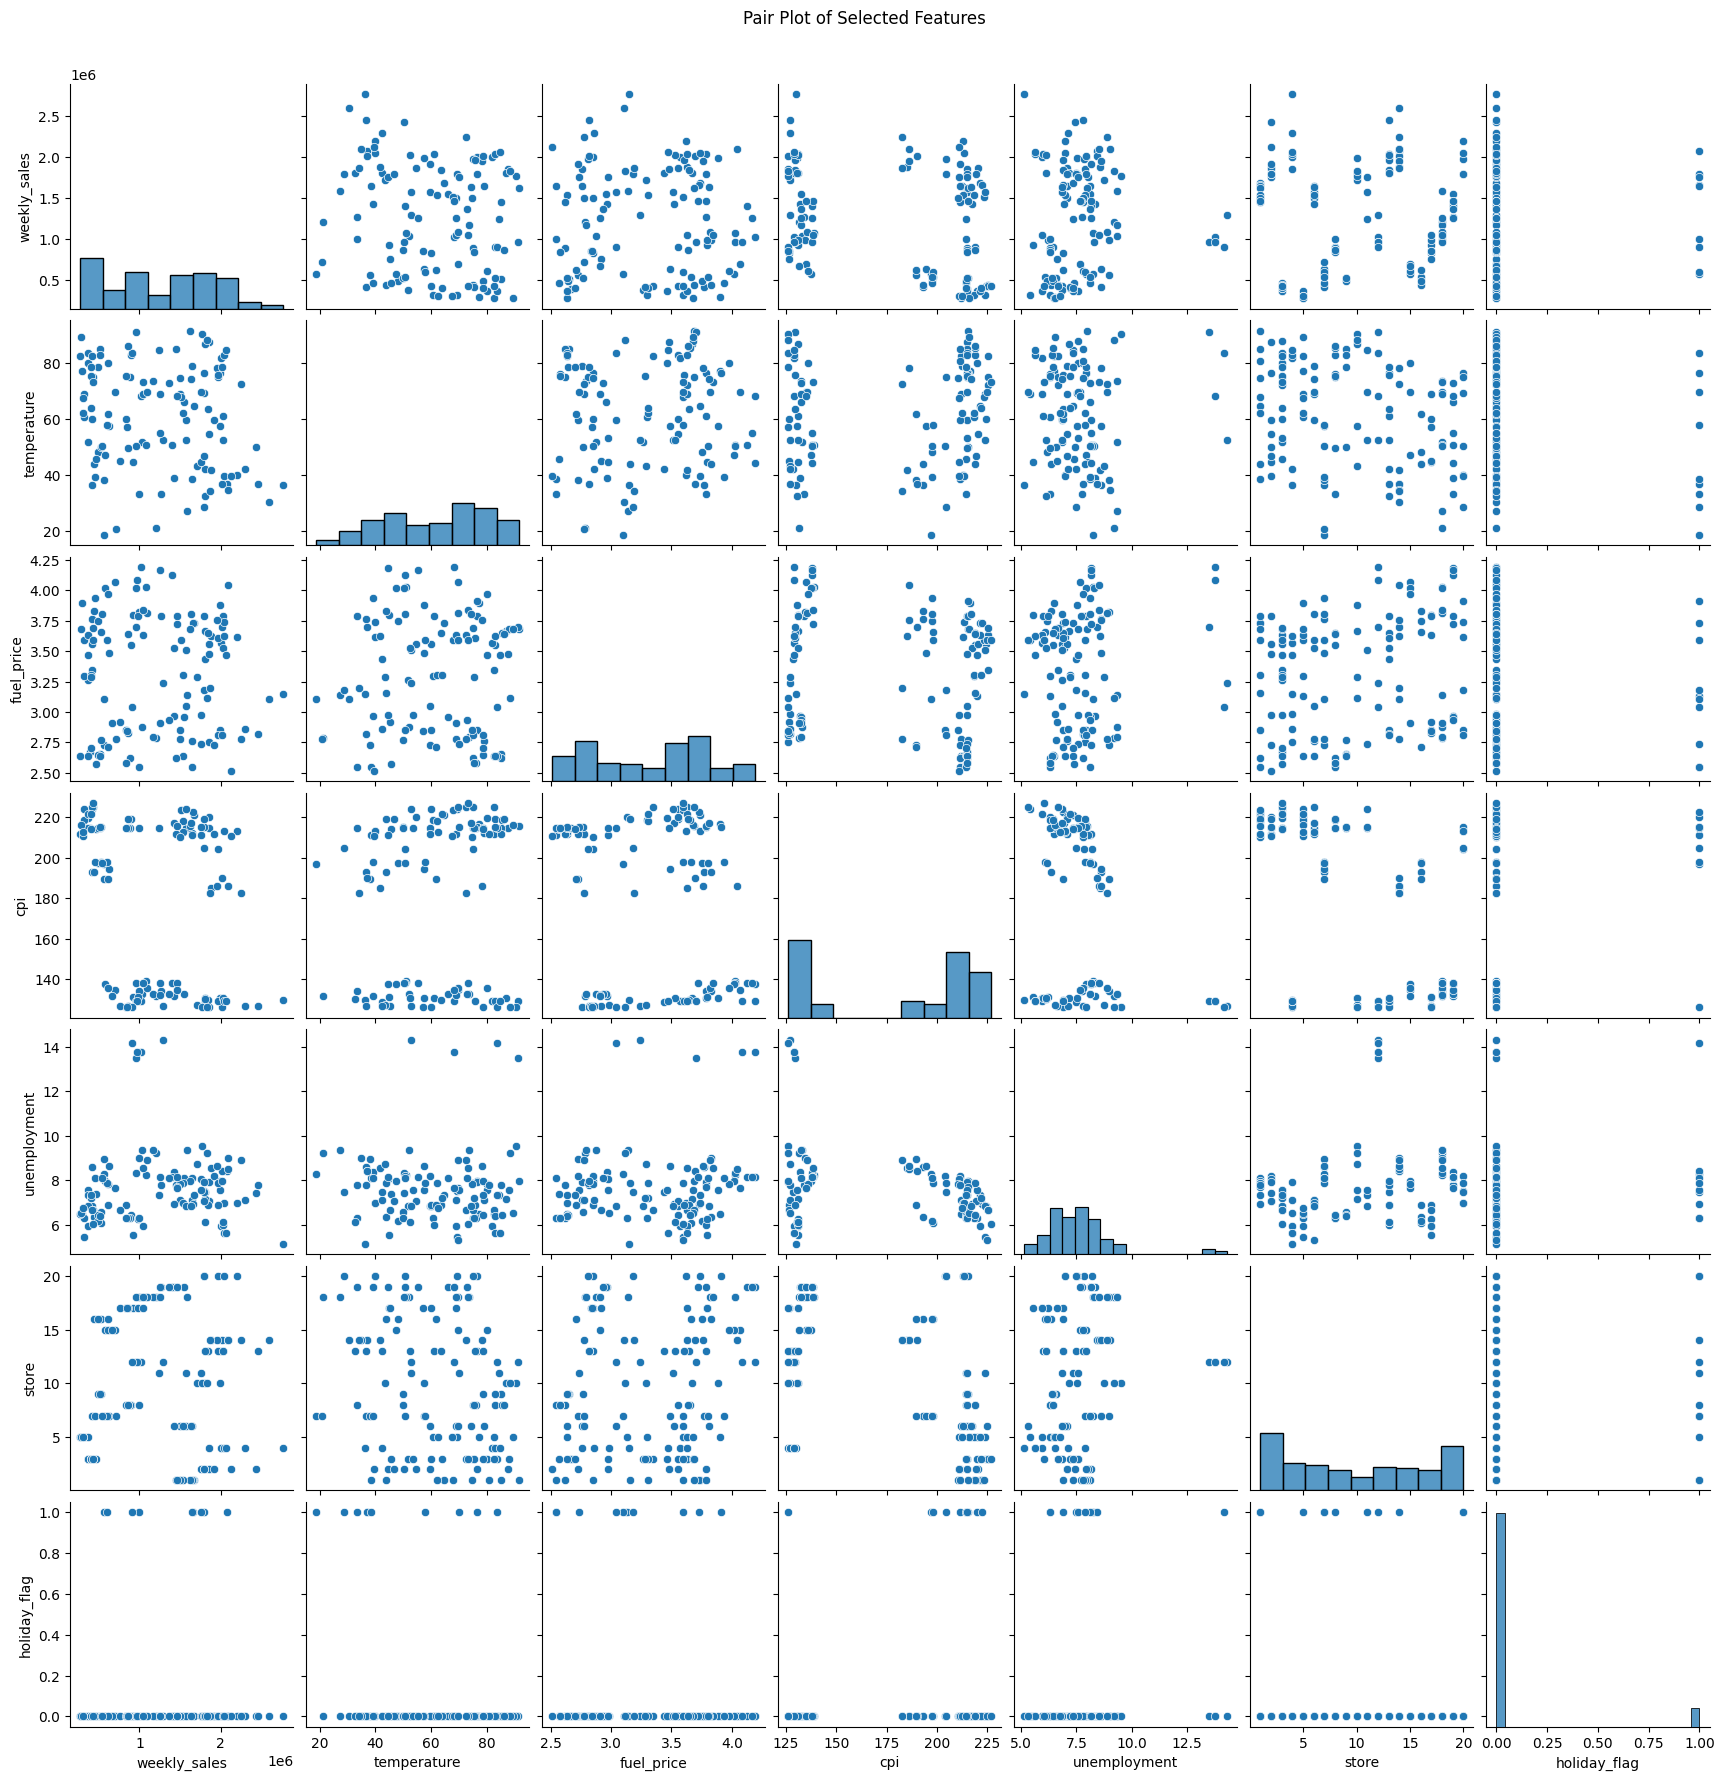

In [288]:
# Plot pairwise relationships between selected features
sns.pairplot(df, vars=['weekly_sales', 'temperature', 'fuel_price','cpi', 'unemployment', 'store', 'holiday_flag'])
plt.suptitle('Pair Plot of Selected Features', y=1.02)
plt.show()

## univariate analysis

target = Weekly_Sales

Dataset de petite taille. Avons-nous suffisamment de données ?

In [ ]:
import plotly.io as pio

print(df.value_counts("weekly_sales"))
fig = px.histogram(df["weekly_sales"], 
                   color_discrete_sequence=px.colors.qualitative.Plotly, 
                   title="Distribution de la variable 'weekly_sales'")
fig.show()

La distribution de la variable exploratoire Weekly_Sales est déséquilibrée, avec une majorité d'achats réalisée en semaine.

Cela peut également poser des problèmes pour l'entraînement d'un modèle de machine learning, car il pourrait être biaisé vers la classe majoritaire.

Il sera important de prendre en compte ce déséquilibre lors du choix des métriques d'évaluation et éventuellement d'utiliser des techniques de rééchantillonnage ou de pondération pour améliorer les performances du modèle sur la classe minoritaire.   

In [ ]:
df.value_counts("store")

print(df.value_counts("store"))
fig = px.histogram(df["store"], 
                   title="Distribution de la variable 'store'", 
                   color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
df_store = df['store'].value_counts().reset_index()
fig = px.pie(df_store.sort_values("store"),
             names = "store", 
             values = "count", 
             title = "Stores proportions", 
             labels={"count": "number"},
             color_discrete_sequence = px.colors.qualitative.Plotly)
fig.show()

Nous observons 20 magasins. Le nombre de relevés varie de 3 à 15 par magasin. Ces enregistrements multiples indiques une variation des variables explicatives date, température, fuel_price, cpi, unemployment.

In [ ]:
print(df.loc[df['store'] == 3])


In [ ]:
date_min = min(df['date'])
date_max = max(df['date'])
print(f'date minimum : {date_min} \ndate maximum : {date_max}')


Les relevés correspondent à la période du 5/02/2010 au 19/10/2012.

In [ ]:
fig = go.Figure(
    data = go.Histogram(
        x = df['date'], nbinsx = df['date'].nunique()),
    layout = go.Layout(
        title = go.layout.Title(text = "Number of observations per day", x = 0.5),
        xaxis = go.layout.XAxis(title = 'X', rangeslider = go.layout.xaxis.Rangeslider(visible = True))
    )
)

fig.show()

Nous observons plusieurs enregistrements par date.

In [ ]:
print(df.loc[df['date'] == '07-01-2011'])

In [ ]:
fig = px.histogram(df["holiday_flag"], 
                   title="Distribution de la variable 'holiday_flag'", 
                   color=df['holiday_flag'],
                   color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

Evidemment, il y a davantage de périodes ouvrées que de congés.

In [ ]:
fig = px.histogram(df["temperature"], title="Distribution de la variable 'Temperature'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

Les données sur la température sont abondantes.

In [ ]:
fig = px.histogram(df["fuel_price"], title="Distribution de la variable 'Fuel_Price'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
fig = px.histogram(df["cpi"], title="Distribution de la variable 'CPI'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
fig = px.histogram(df["Unemployment"], title="Distribution de la variable 'Unemployment'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

## multivariate analysis

In [ ]:
fig = px.bar(df, x="Store", y="Weekly_Sales", color="Store", title="Weekly_Sales per Store")
fig.show() 
# somme des ventes
# système de couleur par store

In [ ]:
fig = px.line(df, x="Date", y="Weekly_Sales", color='Store', title="Weekly_Sales per Date")
fig.show()
# Les dates ne sont pas ordonnées

In [ ]:
fig = px.histogram(df, x="Holiday_Flag", y="Weekly_Sales", color="Holiday_Flag", title="Weekly_Sales per Holiday_Flag", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
pct_weekly_sales_per_holiday_flag = df.groupby("Holiday_Flag")["Weekly_Sales"].sum() / df['Weekly_Sales'] * 100
print(pct_weekly_sales_per_holiday_flag)

fig = px.bar(x='Holiday_Flag', y='pct_weekly_sales_per_holiday_flag', title="Pct weekly sales business days vs holidays", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
mean_sales = df.groupby("Holiday_Flag")["Weekly_Sales"].mean()
rate = (mean_sales[1.0] - mean_sales[0.0]) / mean_sales[0.0] * 100
print(f"Écart des ventes semaines fériées vs non fériées : {rate:.2f} %")

In [ ]:
fig = px.box(df, x="source", y="total_pages_visited", color="Weekly_Sales", title="Distribution des pages visitées par source en fonction de la conversion", color_discrete_sequence=px.colors.qualitative.Pastel)
fig.show()

In [ ]:
rate_conversion_country = df.groupby("country")["converted"].mean() * 100
print(rate_conversion_country)

fig = px.bar(rate_conversion_country, title="Taux de conversion par pays", color=rate_conversion_country.index, color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
rate_user = df.groupby("source")["new_user"].mean().reset_index()
print(rate_user)

fig = px.bar(rate_user, x="source", y="new_user", barmode= "group", title="Taux de nouveaux utilisateurs par source", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
#tx_conversion_user = df.groupby("new_user")["converted"].mean().reset_index()

fig = px.bar(df, x="new_user", y="converted", title="Taux de conversion des nouveaux utilisateurs", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [ ]:
df.to_csv("df.csv", index=False)